In [ ]:
%%html
<center><marquee style='width: 60%; color: blue;'><b>✌ ¡Hola a todos! Un saludo... Vamos a Empezar ✌ </b></marquee><center>

<table>
    <tr>
        <td><img src="https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/logo_ECI.png" width="300"/></td>
        <td>&nbsp;</td>
        <td>
            <h1 style="font-size:200%;color:blue;text-align:center">    <FONT COLOR="blue">  Clustering  </p> Ejemplos k-means     </h1></td>         
        <td>
            <tp><p style="font-size:99%;text-align:center">Ciencia de Datos</p></tp>
            <tp><p style="font-size:115%;text-align:center">Diplomado 2026-2</p></tp>
            <tp><p style="font-size:115%;text-align:center">Prof. Fabián Sánchez</p></tp>
        </td>
    </tr>
</table>

**Objetivo de la sesión**:

Mostrar un par de ejemplos de k-means


In [39]:
# librerías para procesar
import numpy  as np
import pandas as pd

# librerías para graficar
import matplotlib.pyplot as plt
import seaborn           as sns
import plotly.express    as px

# Algunos elementos de preprocesamiento: escalamiento y selección de k en k-means
from sklearn.preprocessing     import StandardScaler
from sklearn.metrics           import silhouette_samples, silhouette_score

# Para el algoritmo k-means
from sklearn.cluster           import KMeans

# Para otros algoritmos de machine learning
from sklearn.decomposition     import PCA
from sklearn.neighbors         import KNeighborsClassifier
from sklearn.neighbors         import NearestNeighbors
from sklearn.metrics           import pairwise_distances_argmin_min

#Para omitir los warnings
import warnings
warnings.filterwarnings("ignore")

# <FONT SIZE=5 COLOR="purple"> 1. Ejemplo 1 de k-means </FONT>

Consideremos el conjunto de datos digits de la librería *sklearn*

In [40]:
from sklearn.datasets import load_digits
from PIL import Image

In [41]:
digits = load_digits()
data = digits.data

Vamos un elemento de este conjunto

In [44]:
data.shape

(1797, 64)

In [42]:
data[1]

array([ 0.,  0.,  0., 12., 13.,  5.,  0.,  0.,  0.,  0.,  0., 11., 16.,
        9.,  0.,  0.,  0.,  0.,  3., 15., 16.,  6.,  0.,  0.,  0.,  7.,
       15., 16., 16.,  2.,  0.,  0.,  0.,  0.,  1., 16., 16.,  3.,  0.,
        0.,  0.,  0.,  1., 16., 16.,  6.,  0.,  0.,  0.,  0.,  1., 16.,
       16.,  6.,  0.,  0.,  0.,  0.,  0., 11., 16., 10.,  0.,  0.])

In [43]:
len(data[1])

64

Observe que son los valores de colores en escalas de grises. Podemos cambiar la escala

In [45]:
data = 255-data

In [46]:
data[1]

array([255., 255., 255., 243., 242., 250., 255., 255., 255., 255., 255.,
       244., 239., 246., 255., 255., 255., 255., 252., 240., 239., 249.,
       255., 255., 255., 248., 240., 239., 239., 253., 255., 255., 255.,
       255., 254., 239., 239., 252., 255., 255., 255., 255., 254., 239.,
       239., 249., 255., 255., 255., 255., 254., 239., 239., 249., 255.,
       255., 255., 255., 255., 244., 239., 245., 255., 255.])

Veamos el elemento gráfico

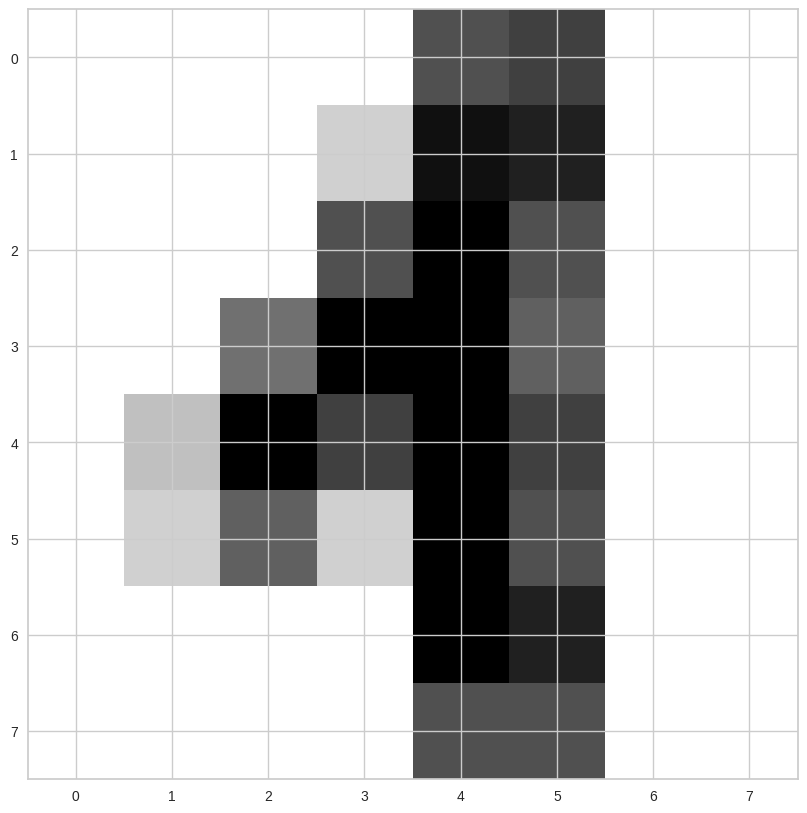

In [51]:
imagen = data[200, ]
imagen = imagen.reshape(8, 8)
plt.imshow(imagen, cmap=plt.cm.gray)

Veamos más elementos

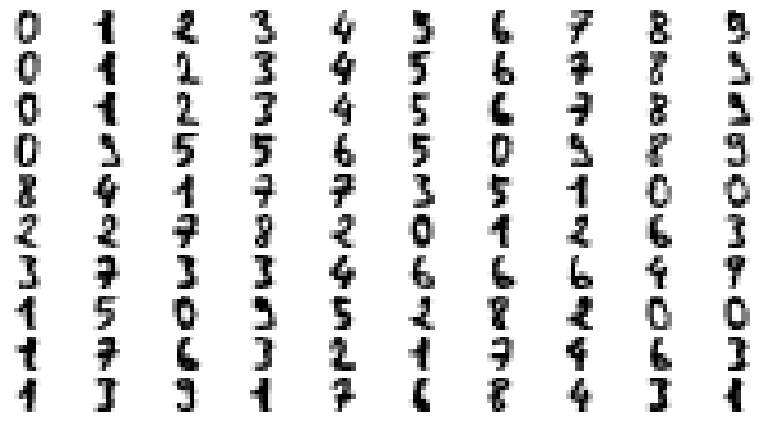

In [52]:
plt.figure(figsize=(10,10))
for k in range(0, 100):
  plt.subplot(19, 10, k+1)
  imagen = data[k, ]
  imagen = imagen.reshape(8, 8)
  plt.imshow(imagen, cmap=plt.cm.gray)
  plt.axis('off')
plt.show()

In [ ]:
print(data.shape)

El objetivo del ejercicio es utilizar *k-means* para agrupar los dígitos.

In [54]:
# fijamos una semilla
np.random.seed(1)

# Generamos el modelo
kmeans = KMeans(n_clusters=10,
                init='random')
kmeans.fit(data)


KMeans(init='random', n_clusters=10)

In [57]:
kmeans.labels_

array([9, 4, 4, ..., 4, 3, 3], shape=(1797,), dtype=int32)

In [55]:
predict = kmeans.predict(data)

In [56]:
# elementos donde se cumple que el clúster es 1
fila = np.where(predict==1)[0]
fila

array([   3,   13,   23,   45,   59,   60,   62,   63,   83,   89,   91,
         92,   98,  133,  143,  153,  161,  175,  189,  190,  192,  193,
        213,  217,  219,  226,  259,  269,  279,  301,  315,  316,  318,
        319,  339,  345,  347,  354,  359,  385,  389,  399,  409,  431,
        445,  469,  475,  477,  484,  489,  561,  576,  614,  619,  649,
        659,  669,  691,  696,  705,  706,  708,  709,  721,  729,  735,
        737,  744,  749,  779,  789,  799,  821,  835,  836,  838,  839,
        859,  865,  867,  874,  879,  908,  918,  928,  947,  950,  961,
        962,  964,  965,  985,  990,  992,  999, 1004, 1032, 1038, 1042,
       1052, 1074, 1086, 1087, 1089, 1090, 1104, 1110, 1116, 1125, 1130,
       1150, 1160, 1170, 1180, 1216, 1217, 1219, 1220, 1240, 1246, 1248,
       1255, 1260, 1290, 1300, 1309, 1310, 1332, 1337, 1338, 1341, 1344,
       1346, 1347, 1349, 1350, 1364, 1370, 1376, 1378, 1385, 1390, 1418,
       1428, 1438, 1460, 1474, 1475, 1477, 1478, 14

In [58]:
# número de imágenes que clasificó en el clúster 1
num = fila.shape[0]
num

176

In [ ]:
for i in range(0,10):

    fila = np.where(predict==i)[0]   # filas en predict donde están las imágenes de cada cluster
    num = fila.shape[0]              # número imagenes de cada cluster
    r = np.floor(num/10.)            # número de filas menos 1 en figura de salida

    print("cluster "+str(i))
    print(str(num)+" elementos")

    plt.figure(figsize=(10,10))
    for k in range(0, num):
        plt.subplot(int(r+1), 10, k+1)
        imagen = data[fila[k], ]
        imagen = imagen.reshape(8, 8)
        plt.imshow(imagen, cmap=plt.cm.gray)
        plt.axis('off')
    plt.show()

**Ejercicio:** Hacer diagramas de barras por cada grupo, donde muestre cuántos clasificó bien y cuántos mal.

In [60]:
import numpy as np
import pandas as pd

# Etiquetas reales de los dígitos
y_real = digits.target  # digits = load_digits()

# Tabla de contingencia
tabla = pd.crosstab(
    pd.Series(predict, name="Cluster"),
    pd.Series(y_real, name="Dígito real")
)

# Agregar el total de elementos por cluster
tabla["Total"] = tabla.sum(axis=1)

print(tabla)

Dígito real    0   1    2    3    4    5    6    7    8    9  Total
Cluster                                                            
0              0   2    0    0    0    1  177    0    2    0    182
1              0   1   13  154    0    0    0    0    2    6    176
2              1   0    0    0  166    2    0    0    0    0    169
3              0   0    2   13    0   43    0    0   51  139    248
4              0  99    8    7    2    0    3    2  101    1    223
5              0   1    0    2    0  136    0    0    4    6    149
6              0  24  147    0    0    0    0    0    3    0    174
7              0   0    4    7   10    0    0  175    5    8    209
8              0  55    2    0    3    0    0    2    6   20     88
9            177   0    1    0    0    0    1    0    0    0    179


In [71]:
px.bar(tabla.drop(columns="Total", axis = 1))

In [63]:
fig = px.bar(tabla.drop(columns="Total"), barmode="group")
fig.show()

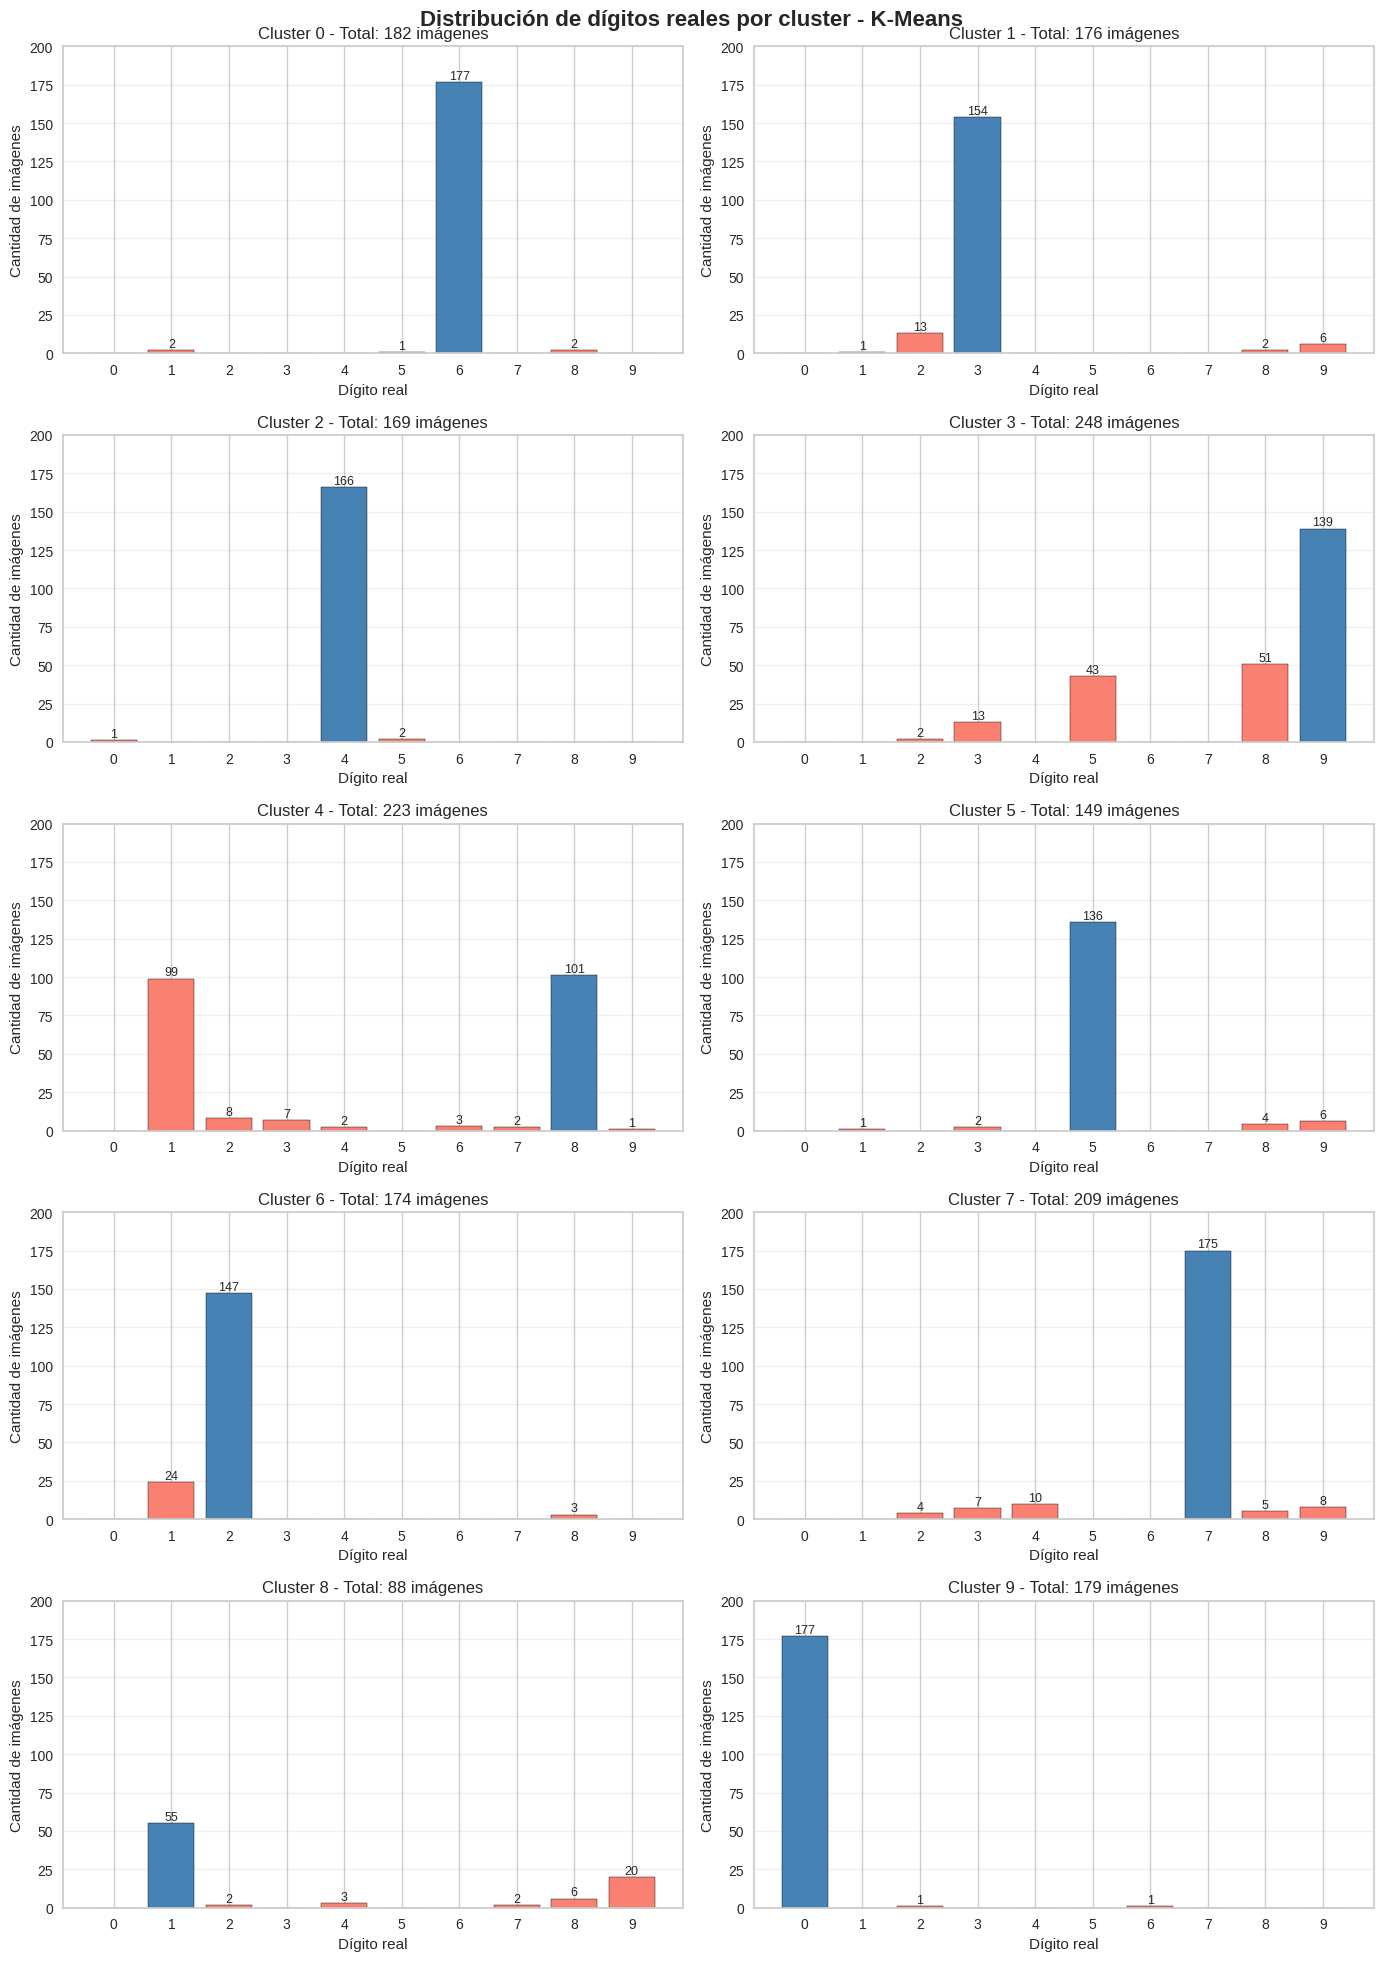

In [61]:
import matplotlib.pyplot as plt
import numpy as np

# Eliminar columna Total
conteos = tabla.drop(columns="Total")

# Crear figura con 10 gráficos (5 filas x 2 columnas)
fig, axes = plt.subplots(5, 2, figsize=(14, 20))

axes = axes.flatten()

for i, cluster in enumerate(conteos.index):

    valores = conteos.loc[cluster]

    # Dígito predominante
    predominante = valores.idxmax()

    # Colores: azul para predominante, rojo para los demás
    colores = [
        "steelblue" if digito == predominante else "salmon"
        for digito in valores.index
    ]

    axes[i].bar(
        valores.index.astype(str),
        valores.values,
        color=colores,
        edgecolor="black"
    )

    axes[i].set_title(
        f"Cluster {cluster} - Total: {valores.sum()} imágenes"
    )

    axes[i].set_xlabel("Dígito real")
    axes[i].set_ylabel("Cantidad de imágenes")

    # Mostrar valores sobre las barras
    for j, valor in enumerate(valores.values):
        if valor > 0:
            axes[i].text(
                j, valor + 2, str(valor),
                ha="center",
                fontsize=9
            )

    axes[i].set_ylim(0, 200)
    axes[i].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Distribución de dígitos reales por cluster - K-Means",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# <FONT SIZE=5 COLOR="purple"> 2. Ejemplo 2 de k-means (calorías) </FONT>


Vamos a considerar los datos de kaggle

https://www.kaggle.com/code/samtam22/exercise-and-calorie-burning-data-analysis

que contienen las siguientes variables.

- **User_Id** : Identificador único para cada individuo del conjunto de datos.

  - Sirve para vincular diferentes registros del mismo usuario (por ejemplo, de dos datasets: uno de ejercicios y otro de calorías).

- **Gender**: Género del usuario.  En los datos suelen estar codificados como: male = 0, female = 1, o viceversa

- **Age** : Edad del usuario en años.

- **Height**: Estatura del usuario, normalmente expresada en centímetros (cm)

- **Weight** : Peso del usuario en kilogramos (kg).

- **Duration**:  Duración del ejercicio o actividad física, generalmente expresada en minutos

- **Heart_Rate**: Frecuencia cardíaca promedio durante el ejercicio, medida en pulsos por minuto (bpm)

- **Body_Temp**: Temperatura corporal promedio durante la actividad, en grados Celsius (°C)

- **Calories**: Calorías quemadas estimadas durante el ejercicio.

Es la variable objetivo en modelos que predicen gasto energético en base a los factores anteriores

In [72]:
calorias = pd.read_csv("https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/calories.csv")
calorias

,User_ID,Calories
0,14733363,231.0
1,14861698,66.0
2,11179863,26.0
3,16180408,71.0
4,17771927,35.0
...,...,...
14995,15644082,45.0
14996,17212577,23.0
14997,17271188,75.0
14998,18643037,11.0


In [73]:
ejercicio = pd.read_csv("https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/exercise.csv")
ejercicio

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8
...,...,...,...,...,...,...,...,...
14995,15644082,female,20,193.0,86.0,11.0,92.0,40.4
14996,17212577,female,27,165.0,65.0,6.0,85.0,39.2
14997,17271188,female,43,159.0,58.0,16.0,90.0,40.1
14998,18643037,male,78,193.0,97.0,2.0,84.0,38.3


Vamos a fusionar los datos

In [74]:
# pegar los dos dataframes
datos = pd.concat([calorias, ejercicio], axis=1)
datos

,User_ID,Calories,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,14733363,231.0,14733363,male,68,190.0,94.0,29.0,105.0,40.8
1,14861698,66.0,14861698,female,20,166.0,60.0,14.0,94.0,40.3
2,11179863,26.0,11179863,male,69,179.0,79.0,5.0,88.0,38.7
3,16180408,71.0,16180408,female,34,179.0,71.0,13.0,100.0,40.5
4,17771927,35.0,17771927,female,27,154.0,58.0,10.0,81.0,39.8
...,...,...,...,...,...,...,...,...,...,...
14995,15644082,45.0,15644082,female,20,193.0,86.0,11.0,92.0,40.4
14996,17212577,23.0,17212577,female,27,165.0,65.0,6.0,85.0,39.2
14997,17271188,75.0,17271188,female,43,159.0,58.0,16.0,90.0,40.1
14998,18643037,11.0,18643037,male,78,193.0,97.0,2.0,84.0,38.3


In [ ]:
# como unir datos con merge.

Vamos a eliminar la variable User_ID

In [75]:
# eliminar User_ID
datos = datos.drop('User_ID', axis=1)
datos

,Calories,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,231.0,male,68,190.0,94.0,29.0,105.0,40.8
1,66.0,female,20,166.0,60.0,14.0,94.0,40.3
2,26.0,male,69,179.0,79.0,5.0,88.0,38.7
3,71.0,female,34,179.0,71.0,13.0,100.0,40.5
4,35.0,female,27,154.0,58.0,10.0,81.0,39.8
...,...,...,...,...,...,...,...,...
14995,45.0,female,20,193.0,86.0,11.0,92.0,40.4
14996,23.0,female,27,165.0,65.0,6.0,85.0,39.2
14997,75.0,female,43,159.0,58.0,16.0,90.0,40.1
14998,11.0,male,78,193.0,97.0,2.0,84.0,38.3


Hacemos una pequeña exploración de los datos

In [76]:
# cabeza de los datos
datos.head()

,Calories,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,231.0,male,68,190.0,94.0,29.0,105.0,40.8
1,66.0,female,20,166.0,60.0,14.0,94.0,40.3
2,26.0,male,69,179.0,79.0,5.0,88.0,38.7
3,71.0,female,34,179.0,71.0,13.0,100.0,40.5
4,35.0,female,27,154.0,58.0,10.0,81.0,39.8


In [77]:
# tamaño de los datos
datos.shape

(15000, 8)

In [78]:
# variables de los datos
datos.columns

Index(['Calories', 'Gender', 'Age', 'Height', 'Weight', 'Duration',
       'Heart_Rate', 'Body_Temp'],
      dtype='object')

In [79]:
# información de los datos
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Calories    15000 non-null  float64
 1   Gender      15000 non-null  object 
 2   Age         15000 non-null  int64  
 3   Height      15000 non-null  float64
 4   Weight      15000 non-null  float64
 5   Duration    15000 non-null  float64
 6   Heart_Rate  15000 non-null  float64
 7   Body_Temp   15000 non-null  float64
dtypes: float64(6), int64(1), object(1)
memory usage: 937.6+ KB


In [80]:
# estadística de los datos
datos.describe()

,Calories,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,89.539533,42.789800,174.465133,74.966867,15.530600,95.518533,40.025453
std,62.456978,16.980264,14.258114,15.035657,8.319203,9.583328,0.779230
min,1.000000,20.000000,123.000000,36.000000,1.000000,67.000000,37.100000
25%,35.000000,28.000000,164.000000,63.000000,8.000000,88.000000,39.600000
50%,79.000000,39.000000,175.000000,74.000000,16.000000,96.000000,40.200000
75%,138.000000,56.000000,185.000000,87.000000,23.000000,103.000000,40.600000
max,314.000000,79.000000,222.000000,132.000000,30.000000,128.000000,41.500000


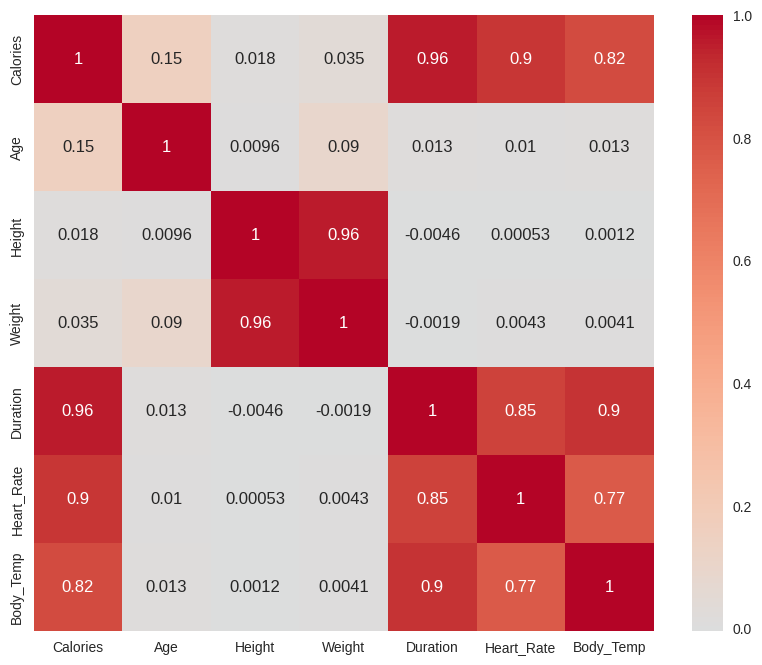

In [81]:
# mapa de correlaciones de las variables numéricas con seaborn
num_cols = datos.select_dtypes(include=["number"])
corr = num_cols.corr()
# Mapa de calor
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True,
            xticklabels=num_cols.columns,
            yticklabels=num_cols.columns,
            cmap="coolwarm", center=0)
plt.show()

In [82]:
# gender convertir a 1 y 0
datos.Gender.replace({"male":1, "female":0}, inplace= True)

In [83]:
datos.head()

,Calories,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,231.0,1,68,190.0,94.0,29.0,105.0,40.8
1,66.0,0,20,166.0,60.0,14.0,94.0,40.3
2,26.0,1,69,179.0,79.0,5.0,88.0,38.7
3,71.0,0,34,179.0,71.0,13.0,100.0,40.5
4,35.0,0,27,154.0,58.0,10.0,81.0,39.8


Escalamos los datos

In [87]:
# libreria para MinMaxScaler
from sklearn.preprocessing import MinMaxScaler

# Escalamos los datos
scaler = MinMaxScaler() # para variables continuas es recomendable StandardScaler / RobustScaler
scaler.fit(datos)
df = pd.DataFrame(scaler.transform(datos),
                  columns = datos.columns,
                  index = datos.index)
df.head(6)

,Calories,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,0.734824,1.0,0.813559,0.676768,0.604167,0.965517,0.622951,0.840909
1,0.207668,0.0,0.000000,0.434343,0.250000,0.448276,0.442623,0.727273
2,0.079872,1.0,0.830508,0.565657,0.447917,0.137931,0.344262,0.363636
3,0.223642,0.0,0.237288,0.565657,0.364583,0.413793,0.540984,0.772727
4,0.108626,0.0,0.118644,0.313131,0.229167,0.310345,0.229508,0.613636
5,0.389776,0.0,0.271186,0.282828,0.145833,0.758621,0.475410,0.818182


Utilizamos el método del codo para tener una idea de cuántos clusters deberíamos hacer

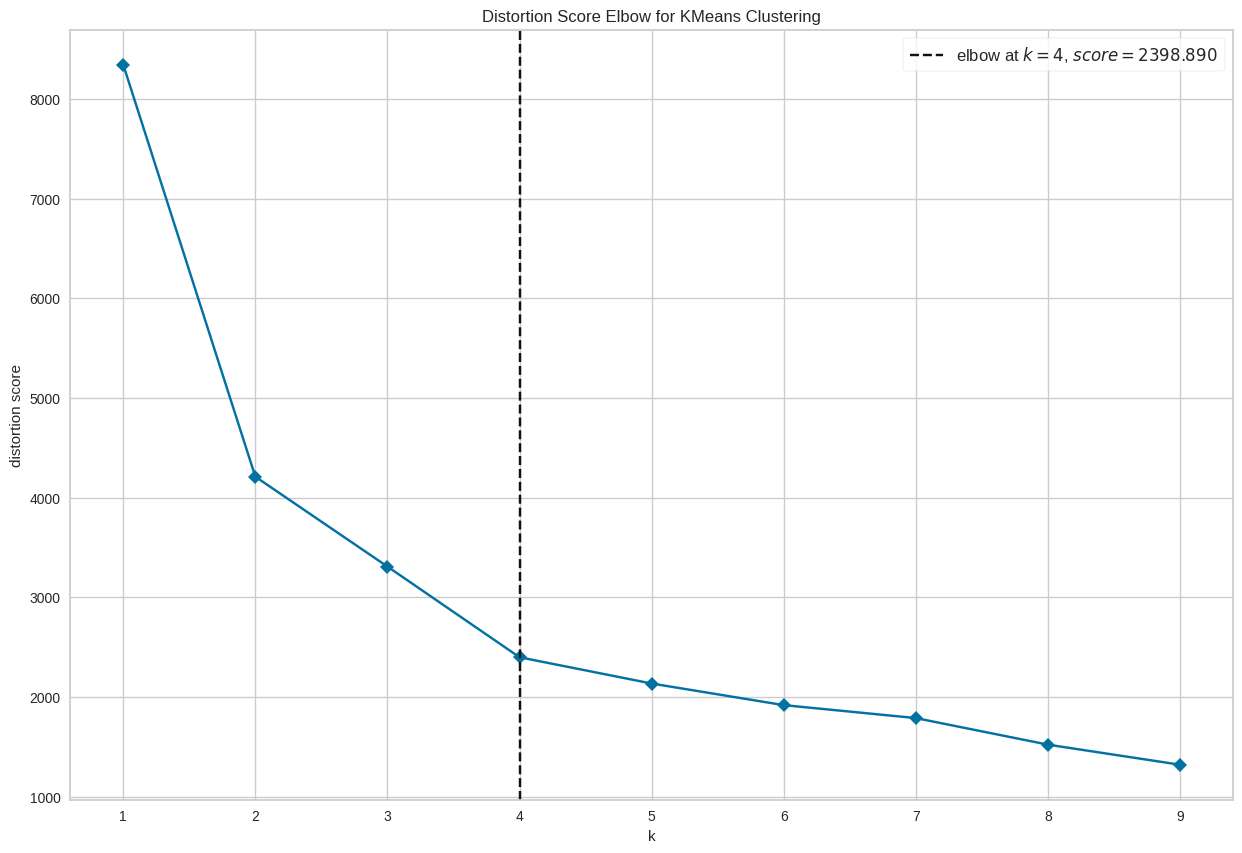

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [88]:
from yellowbrick.cluster import KElbowVisualizer
model = KMeans()                                          # definimos el modelo
visualizer = KElbowVisualizer(model,                      # definimos el visualizador
                              k=(1,10),                   # intervalo de los valores de k
                              timings=False)              # para que no aparezca fit-time
visualizer.fit(df)                                        # Entrenamos con los datos
visualizer.show(show=False)                               # mostramos la gráfica

Hacemos el modelo

In [89]:
# generación del modelo con cuatro clusters
n = 4
kmeans = KMeans(n_clusters=n,                  #Número de clusters
                random_state=0)                #Semilla aleatoria.
kmeans.fit(df)

KMeans(n_clusters=4, random_state=0)

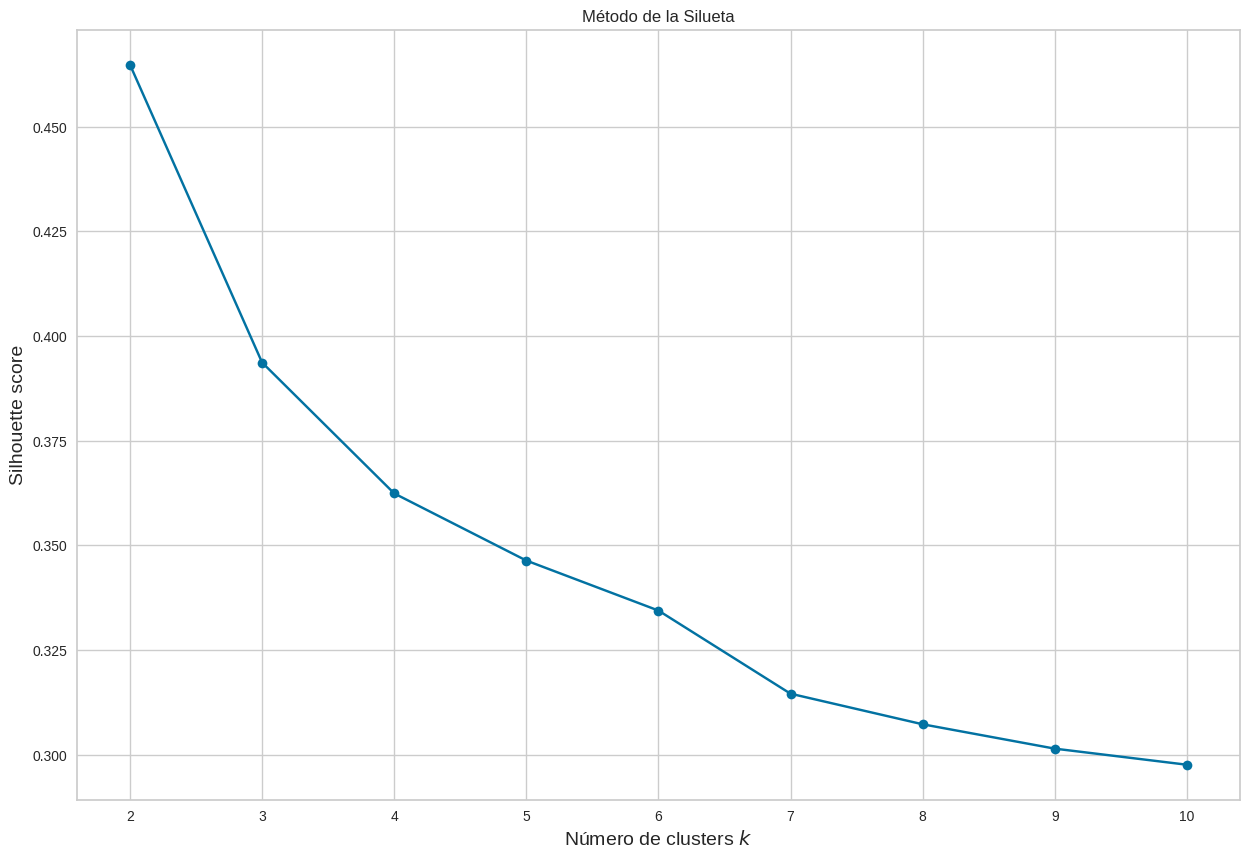

In [95]:
# generación de los modelos para diferentes valores de $k$
models = [KMeans(n_clusters=n, random_state=0 ).fit(df) for n in range(2,11)]
silhouette_scores = [silhouette_score(df, model.labels_) for model in models]

# gráficamos los valores de la silueta para cada valor de k
plt.plot(list(range(2, 11)), silhouette_scores, "bo-")
plt.xlabel("Número de clusters $k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.title("Método de la Silueta")
plt.show()

In [ ]:
datos.head()

In [90]:
kmeans.labels_

array([2, 0, 1, ..., 0, 1, 2], shape=(15000,), dtype=int32)

Pegamos las etiquetas a los datos para poder analizarlos

In [91]:
# Caso 4 clusters
df_Clusters = datos.copy()
df_Clusters["cluster"] = kmeans.labels_
df_Clusters

,Calories,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,cluster
0,231.0,1,68,190.0,94.0,29.0,105.0,40.8,2
1,66.0,0,20,166.0,60.0,14.0,94.0,40.3,0
2,26.0,1,69,179.0,79.0,5.0,88.0,38.7,1
3,71.0,0,34,179.0,71.0,13.0,100.0,40.5,0
4,35.0,0,27,154.0,58.0,10.0,81.0,39.8,0
...,...,...,...,...,...,...,...,...,...
14995,45.0,0,20,193.0,86.0,11.0,92.0,40.4,0
14996,23.0,0,27,165.0,65.0,6.0,85.0,39.2,0
14997,75.0,0,43,159.0,58.0,16.0,90.0,40.1,0
14998,11.0,1,78,193.0,97.0,2.0,84.0,38.3,1


In [93]:
df_Clusters.cluster.value_counts()

,count
cluster,
3,3857
1,3827
0,3696
2,3620


Ahora, lo que sigue es analizar los grupos.

In [94]:
# agrupación de la variable *gender*
df_Clusters.groupby(by = ["Gender"]).Calories.describe()

,count,mean,std,min,25%,50%,75%,max
Gender,,,,,,,,
0,7553.0,88.153052,58.586980,2.0,36.0,80.0,135.0,240.0
1,7447.0,90.945750,66.125478,1.0,34.0,78.0,140.0,314.0


In [ ]:
# hacer una crosstab de gender y cluster para el conjunto datos (tabla de contingencia)
pd.crosstab(df_Clusters.Gender, df_Clusters.cluster)

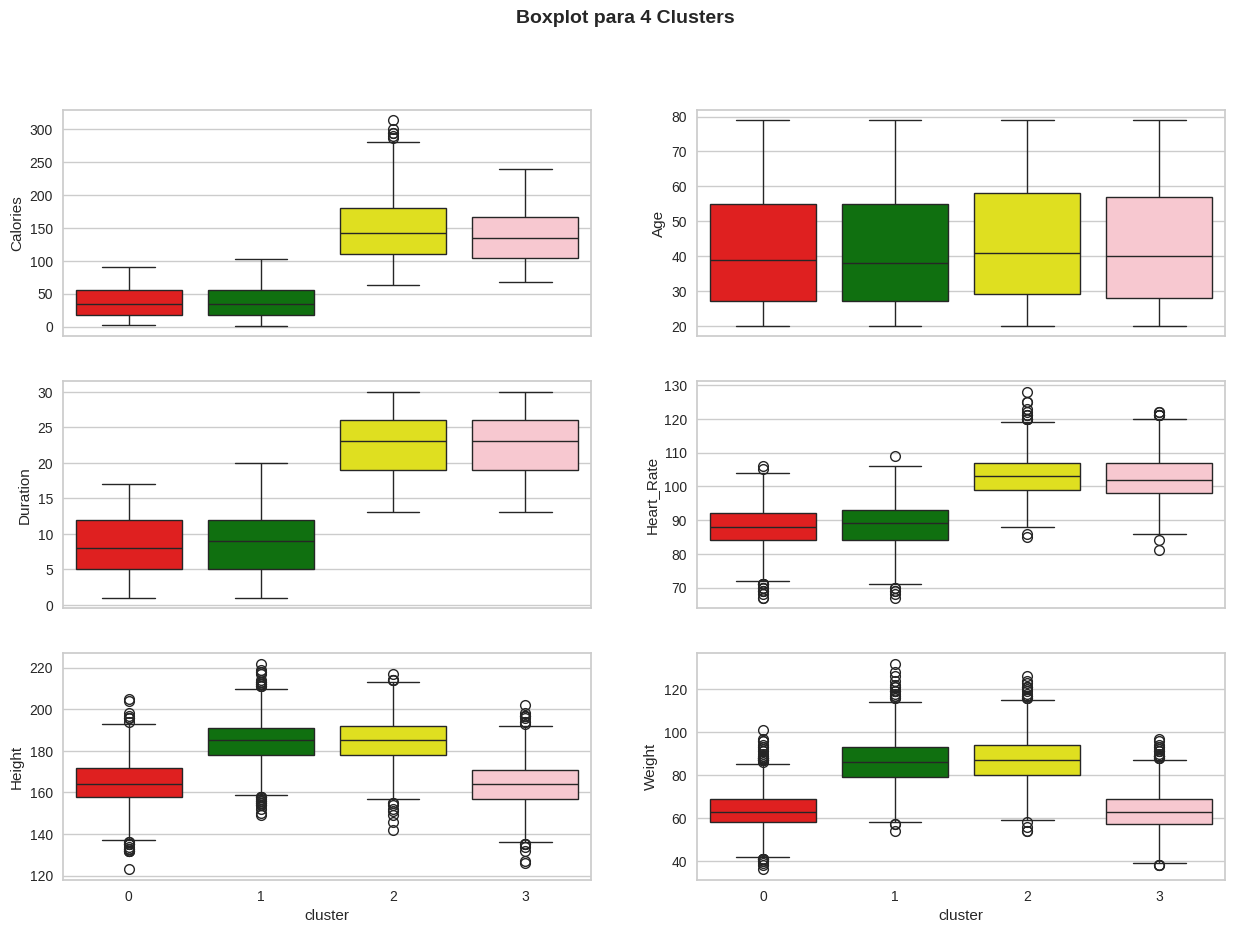

In [92]:
# Box-plots
plt.rcParams["figure.figsize"] = (15,10)
fig, axes = plt.subplots(3, 2 , sharex=True)
my_colors2 ={"0": "red" , "1" : "green" , "2" : "yellow" , "3" : "pink"}
sns.boxplot(data=df_Clusters, x = "cluster", y = "Calories", palette = my_colors2, ax = axes[0,0])
sns.boxplot(data=df_Clusters, x = "cluster", y = "Age", palette = my_colors2, ax = axes[0,1])
sns.boxplot(data=df_Clusters, x = "cluster", y = "Duration", palette = my_colors2,ax = axes[1,0])
sns.boxplot(data=df_Clusters, x = "cluster", y = "Heart_Rate", palette = my_colors2,ax = axes[1,1])
sns.boxplot(data=df_Clusters, x = "cluster", y = "Height", palette = my_colors2,ax = axes[2,0])
sns.boxplot(data=df_Clusters, x = "cluster", y = "Weight", palette = my_colors2,ax = axes[2,1])
fig.suptitle("Boxplot para 4 Clusters", fontsize=14, fontweight="bold",)
plt.show()

In [106]:
df_Clusters.groupby(by = ["cluster"]).Calories.describe()

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
0,3696.0,37.420725,21.774666,2.0,18.0,35.0,56.0,90.0
1,3827.0,37.189182,23.290788,1.0,17.0,35.0,56.0,103.0
2,3620.0,147.776243,46.222580,63.0,110.0,142.0,180.0,314.0
3,3857.0,136.767695,37.909554,67.0,104.0,134.0,166.0,240.0


In [105]:
df_Clusters.groupby(by = ["cluster"]).Duration.describe()

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
0,3696.0,8.149892,4.145949,1.0,5.0,8.0,12.0,17.0
1,3827.0,8.680690,4.386151,1.0,5.0,9.0,12.0,20.0
2,3620.0,22.831492,4.242354,13.0,19.0,23.0,26.0,30.0
3,3857.0,22.547576,4.322380,13.0,19.0,23.0,26.0,30.0


In [110]:
df_Clusters.groupby(by = ["cluster"])[["Calories" , "Age" , "Heart_Rate"]].mean()

,Calories,Age,Heart_Rate
cluster,,,
0,37.420725,42.241342,87.887175
1,37.189182,41.783643,88.467207
2,147.776243,43.966851,103.202486
3,136.767695,43.208971,102.616023


In [96]:
n = 2
kmeans2 = KMeans(n_clusters=n,                  #Número de clusters
                random_state=0)                #Semilla aleatoria.
kmeans2.fit(df)

KMeans(n_clusters=2, random_state=0)

In [98]:
kmeans2.labels_

array([1, 0, 1, ..., 0, 1, 1], shape=(15000,), dtype=int32)

In [99]:
# Caso 2 clusters
df_Clusters2 = datos.copy()
df_Clusters2["cluster"] = kmeans2.labels_
df_Clusters2

,Calories,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,cluster
0,231.0,1,68,190.0,94.0,29.0,105.0,40.8,1
1,66.0,0,20,166.0,60.0,14.0,94.0,40.3,0
2,26.0,1,69,179.0,79.0,5.0,88.0,38.7,1
3,71.0,0,34,179.0,71.0,13.0,100.0,40.5,0
4,35.0,0,27,154.0,58.0,10.0,81.0,39.8,0
...,...,...,...,...,...,...,...,...,...
14995,45.0,0,20,193.0,86.0,11.0,92.0,40.4,0
14996,23.0,0,27,165.0,65.0,6.0,85.0,39.2,0
14997,75.0,0,43,159.0,58.0,16.0,90.0,40.1,0
14998,11.0,1,78,193.0,97.0,2.0,84.0,38.3,1


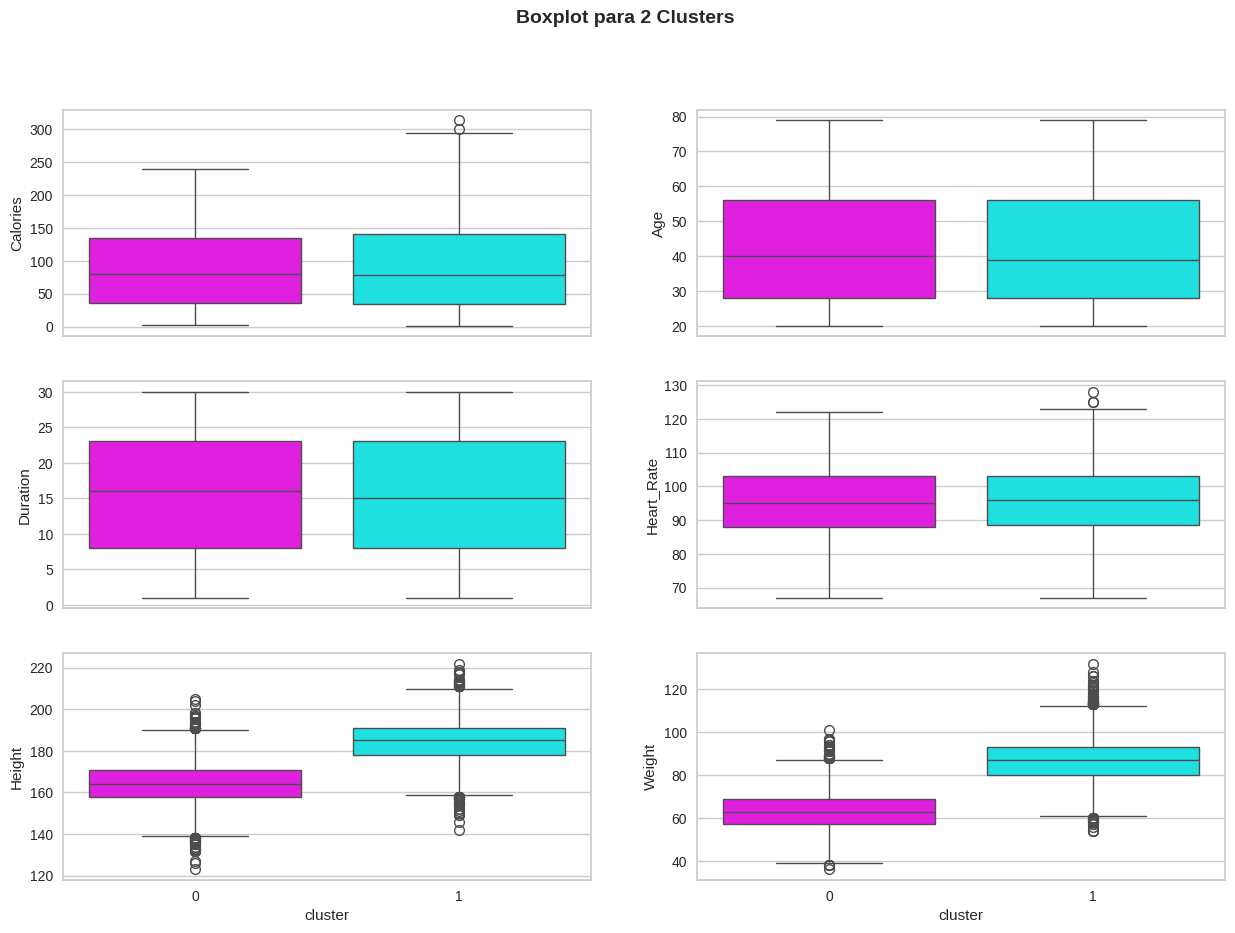

In [100]:
# Box-plots
plt.rcParams["figure.figsize"] = (15,10)
fig, axes = plt.subplots(3, 2 , sharex=True)
my_colors2 ={"0": "magenta" , "1" : "cyan"}
sns.boxplot(data=df_Clusters2, x = "cluster", y = "Calories", palette = my_colors2, ax = axes[0,0])
sns.boxplot(data=df_Clusters2, x = "cluster", y = "Age", palette = my_colors2, ax = axes[0,1])
sns.boxplot(data=df_Clusters2, x = "cluster", y = "Duration", palette = my_colors2,ax = axes[1,0])
sns.boxplot(data=df_Clusters2, x = "cluster", y = "Heart_Rate", palette = my_colors2,ax = axes[1,1])
sns.boxplot(data=df_Clusters2, x = "cluster", y = "Height", palette = my_colors2,ax = axes[2,0])
sns.boxplot(data=df_Clusters2, x = "cluster", y = "Weight", palette = my_colors2,ax = axes[2,1])
fig.suptitle("Boxplot para 2 Clusters", fontsize=14, fontweight="bold",)
plt.show()

In [ ]:
sil_scores = {}
for k in range(2, 11):   # probar entre 2 y 10 clusters
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(df)
    sil = silhouette_score(df, labels)
    sil_scores[k] = sil
    print(f"k={k}, silhouette={sil:.4f}")

# ---------- Mejor k ----------
best_k = max(sil_scores, key=sil_scores.get)
print("\nMejor número de clusters según silueta:", best_k)

In [ ]:
# diagrama de dispersión Age vs Duration color por cluster
px.scatter(df_Clusters,
           x='Calories',
           y='Duration',
           color = "cluster")

In [ ]:
fig = px.scatter_3d(df_Clusters, x='Body_Temp', y='Duration', z='Calories', color = "cluster")
fig.show()
fig.write_html("/content/file2.html")

In [ ]:
fig = px.scatter_3d(df_Clusters, x='Age', y='Duration', z='Calories', color = "cluster")
fig.show()
fig.write_html("/content/file.html")

Ahora, veamos que nos sugiere el método de la silueta

In [ ]:
# generación de los modelos para diferentes valores de $k$
models = [KMeans(n_clusters=n, random_state=0 ).fit(df) for n in range(2,11)]
silhouette_scores = [silhouette_score(df, model.labels_) for model in models]

# gráficamos los valores de la silueta para cada valor de k
plt.plot(list(range(2, 11)), silhouette_scores, "bo-")
plt.xlabel("Número de clusters $k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.title("Método de la Silueta")
plt.show()

In [ ]:
%%html
<center><marquee style='width: 60%; color: blue;'><b>Muchas gracias por asistir a la clase</b></marquee><center>

# <FONT SIZE=5 COLOR="purple">  3. Ejemplo 3. Aplicado PCA + K-means </FONT>

Consideremos el conjunto de datos clásico de mnist de la librería keras. Este conjunto se usa mucho para redes neuronales y en internet hay muchos ejemplos con este conjunto.

Vamos a importar las librerías

In [ ]:
# importamos keras para el conjunto de datos
import keras
from keras.datasets import fashion_mnist
# importamos kmeans
from sklearn.cluster import KMeans

El conjunto de datos que vamos a usar, viene distribuido en dos partes ya que nos sirve para problemas de clasificación.

In [ ]:
(X_train,y_train), (X_test,y_test) = fashion_mnist.load_data()

In [ ]:
# Seleccionar 400 imágenes (puedes hacer shuffle si quieres aleatoriedad)
n_images = 400
images = X_train[:n_images]

# Crear figura y ejes
fig, axes = plt.subplots(20, 20, figsize=(10, 10))

# Eliminar espacios entre celdas
plt.subplots_adjust(wspace=0.1, hspace=0.1)

# Rellenar la cuadrícula
for i in range(20):
    for j in range(20):
        idx = i * 20 + j
        axes[i, j].imshow(images[idx], cmap='gray')
        axes[i, j].axis('off')  # Ocultar ejes

plt.suptitle("Fashion MNIST - 400 imágenes", fontsize=16)
plt.show()

In [ ]:
X_train.shape

Para el propósito de este ejercicio solamente vamos a tomar el conjunto de entrenamiento.


In [ ]:
# debemos redimensionar los datos. como es 28 x 28 = 784
imagenes = X_train.reshape(-1,X_train.shape[1]*X_train.shape[2])
imagenes.shape

In [ ]:
# llamaremos y a los labels
y = y_train
y.shape

La variable y está dada de forma numérica, pero en realidad es una codificación de lo siguiente:

0 --->  Tshirt

1 --->  Trouser

2 --->  Pullover

3 --->  Dress

4 --->  Coat

5 --->  Sandal

6 --->  Shirt

7 --->  Sneaker

8 --->  Bag

9 --->  Ankle Boot

Visualicemos algunos elementos

In [ ]:
# podemos cambiar el número n
n= 10
plt.imshow(imagenes[n].reshape(X_train.shape[1], X_train.shape[2]), cmap = plt.cm.binary)
plt.show()
y[n]

La idea del ejercicio es reducir la dimensionalidad para luego aplicar k-means y hacer el proceso de clustering

## <FONT SIZE=5 COLOR="purple">  4.1 Aplicar PCA </FONT>

In [ ]:
# primero debeos escalar los datos
imagenes_est = StandardScaler().fit_transform(imagenes)

In [ ]:
from sklearn.decomposition import PCA
#vamos a definir la varianza que queremos acumular
varianza = 0.98
pca = PCA(varianza)

In [ ]:
#entreno el PCA
pca.fit(imagenes_est)

Veamos el número de componentes

In [ ]:
pca.n_components_

Ahora, vamos a transformar nuestros datos

In [ ]:
#Transformar los datos de acuerdo con el PCA definido
imagenes_pca = pca.transform(imagenes_est)

In [ ]:
# dimensión después del PCA
imagenes_pca.shape

In [ ]:
#Vamos a definir la transformada inversa para poder visualizar los elementos a partir de la transformación
approx = pca.inverse_transform(imagenes_pca)
approx.shape

Vamos a reconstruir las imágenes usando menos información

In [ ]:
#Reconstrucción de las imágenes con menos información
plt.figure(figsize=(8,4));

# un valor de n para el objeto del dataframe
n = 100

# Imagen Original
plt.subplot(1, 2, 1);
plt.imshow(imagenes[n].reshape(X_train.shape[1],X_train.shape[2]), # basicamente X_train.shape[1] = 28
           cmap = plt.cm.gray,);
plt.xlabel(str(imagenes.shape[1])+" variables", fontsize = 14)
plt.title("Imagen Original", fontsize = 14);

# Imagen con las componentes
plt.subplot(1, 2, 2);
plt.imshow(approx[n].reshape(X_train.shape[1], X_train.shape[2]),
           cmap = plt.cm.gray,);
plt.xlabel(str(imagenes_pca.shape[1]) +" componentes", fontsize = 14)
plt.title(str(varianza * 100) + '% de Varianza retenida', fontsize = 14);

print(y_train[n])

## <FONT SIZE=5 COLOR="purple">  4.2 Aplicar K-means </FONT>

In [ ]:
k_means = KMeans(init = "k-means++",
                 n_clusters = 10,
                 n_init = 35)

**init="k-means++"**

- Utiliza el algoritmo KMeans++ para elegir los centroides iniciales de forma inteligente.

- Mejora la estabilidad del algoritmo y reduce el riesgo de caer en un mal mínimo local.

Es mejor que usar centroides aleatorios (init="random").

**n_clusters=10**

- Es el número de grupos y tomaremos 10 por las clases que hay en el conjunto.

**n_init=35**

- Significa que el algoritmo KMeans se ejecutará 35 veces con diferentes centroides iniciales.

- Luego elegirá la mejor solución (la que tenga el menor error de agrupamiento, o inercia).

- Más repeticiones = más probabilidades de encontrar una buena solución.

In [ ]:
#vamos a entrenar el modelo de kmeans para nuestros datos_pca
k_means.fit(imagenes_pca)

In [ ]:
# recomendación -- guardar el modelo
import joblib
# guardar
joblib.dump(k_means, 'kmeans_model.joblib')
# cargar
#k_means = joblib.load('kmeans_model.joblib')

In [ ]:
# verificamos los labels o etiquetas
k_means_labels = k_means.labels_
print("La lista de los labels de los clusters son " + str(np.unique(k_means_labels)))

In [ ]:
# número de labels
num_lab = len(np.unique(k_means_labels))

#Veamos los elementos que pertenecen a cada label o etiqueta
cluster_index= [[] for i in range(num_lab)]
for i, label in enumerate(k_means_labels,0):
    for n in range(num_lab):
        if label == n:
            cluster_index[n].append(i)
        else:
            continue

In [ ]:
# veamos los primeros 10 indices algunos label
print("registros del label 0", cluster_index[0][0:10])
print("registros del label 1", cluster_index[1][0:10])
print("registros del label 2", cluster_index[2][0:10])

Ahora, vamos a visualizar algunos clusters

In [ ]:
#Visualización de algunos clusters
# establecemos el tamaño de la figura
plt.figure(figsize=(20,20));
# definimos el número de cluster que queremos visualizar
clust = 8
# definimos el número de elementos a visualizar
num = 100
for i in range(1,num):
    # número de filas, número de columnas por filas, iterador
    plt.subplot(10, 10, i);
    plt.imshow(imagenes[cluster_index[clust][i+500]].reshape(X_train.shape[1], X_train.shape[2]), cmap = plt.cm.binary);
plt.show()